In [1]:
import pandas as pd

#### READING THE DATASET

In [2]:
df = pd.read_csv("Online Retail.csv",encoding="latin1")

In [3]:
# latin1 was used to fix unicodedecode error.This usually means Pandas cannote decode the file using its default text encoding.b

In [4]:
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 8.26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 8.26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 8.26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 8.26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 8.26,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,09-12-2011 12.50,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,09-12-2011 12.50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,09-12-2011 12.50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,09-12-2011 12.50,4.15,12680.0,France


# PART 1

## Exploratory Data Analysis

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


In [6]:
df.shape

(541909, 8)

In [7]:
df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [8]:
df.isnull()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...
541904,False,False,False,False,False,False,False,False
541905,False,False,False,False,False,False,False,False
541906,False,False,False,False,False,False,False,False
541907,False,False,False,False,False,False,False,False


In [9]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [10]:
df.duplicated()

0         False
1         False
2         False
3         False
4         False
          ...  
541904    False
541905    False
541906    False
541907    False
541908    False
Length: 541909, dtype: bool

In [11]:
print(df.duplicated().sum())

5268


##### after doing eda i found that there is only null values in customer id and description
#####  and there are 5268 duplicate values.

#### Checking outliers

##### My target variable is quantity ,so I am checking outliers in Quantity and Unitprice

###### BOX PLOT

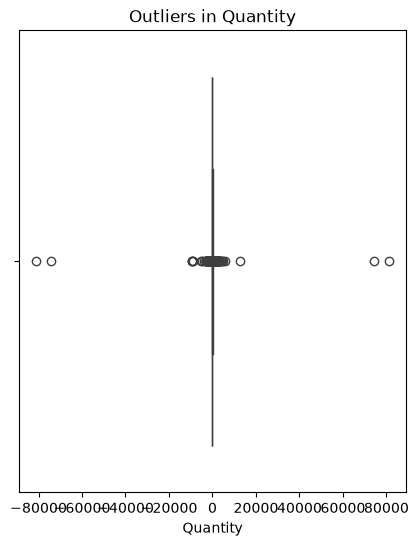

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(5,6))
sns.boxplot(x=df['Quantity'])
plt.title("Outliers in Quantity")
plt.show()

In [13]:
#the visulaization shows several extreme values beyond the normal range.
#indicating unusal quantity transactions in the dataset.

### Box plot for unit price

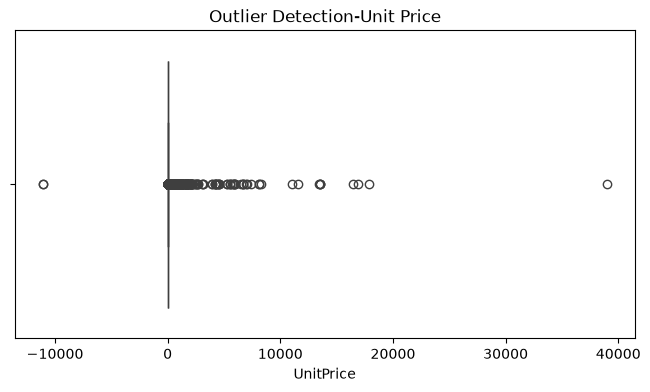

In [14]:

plt.figure(figsize=(8,4))
sns.boxplot(x=df['UnitPrice'])
plt.title("Outlier Detection-Unit Price")
plt.show()
            

In [15]:
#a box plot was created to identify outliers in the unit price.
# the plot shows that several extreme values(high positive and negative)

### Calculating IQR

In [16]:
Q1 = df["Quantity"].quantile(0.25)
Q3 = df["Quantity"].quantile(0.75)
IQR = Q3 -Q1
lower_limit = Q1-1.5*IQR
upper_limit = Q3+1.5*IQR
print("Lower limit:",lower_limit)
print("Upper limit:",upper_limit)

Lower limit: -12.5
Upper limit: 23.5


##### counting outliers

In [17]:
outliers =df[
    (df['Quantity']<lower_limit)|
    (df['Quantity']>upper_limit)
    ]
print("Number of outliers:",outliers)

Number of outliers:        InvoiceNo StockCode                         Description  Quantity  \
9         536367     84879       ASSORTED COLOUR BIRD ORNAMENT        32   
26        536370     22728           ALARM CLOCK BAKELIKE PINK        24   
27        536370     22727           ALARM CLOCK BAKELIKE RED         24   
30        536370     21883                    STARS GIFT TAPE         24   
31        536370     10002         INFLATABLE POLITICAL GLOBE         48   
...          ...       ...                                 ...       ...   
541876    581585     84945  MULTI COLOUR SILVER T-LIGHT HOLDER        24   
541882    581585     21916     SET 12 RETRO WHITE CHALK STICKS        24   
541883    581585     84692         BOX OF 24 COCKTAIL PARASOLS        25   
541891    581586     23275    SET OF 3 HANGING OWLS OLLIE BEAK        24   
541892    581586     21217       RED RETROSPOT ROUND CAKE TINS        24   

             InvoiceDate  UnitPrice  CustomerID         Country  
9

In [18]:
#check the minimum and maximum
print(df['Quantity'].min())
print(df['Quantity'].max())

-80995
80995


In [19]:
# Count negative quantities

df[df['Quantity'] < 0].head(10)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,01-12-2010 9.41,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,01-12-2010 9.49,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,01-12-2010 10.24,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,01-12-2010 10.24,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,01-12-2010 10.24,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,01-12-2010 10.24,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,01-12-2010 10.24,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,01-12-2010 10.24,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,01-12-2010 10.24,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,01-12-2010 12.38,4.25,17897.0,United Kingdom


In [20]:
## count positive quantities
df[df['Quantity'] > 0].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 8.26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 8.26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 8.26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 8.26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 8.26,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,01-12-2010 8.26,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,01-12-2010 8.26,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,01-12-2010 8.28,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,01-12-2010 8.28,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,01-12-2010 8.34,1.69,13047.0,United Kingdom


## DATA PREPROCESSING

In [21]:
#handling missing values
#removing duplicates
#handling negatives values.
#handling outliers
#correcting data 
#preparing the dataset for modelling

In [22]:
#before moving to the data preprocessing i am making a copy of the dataset , to preserve the original dataset

In [23]:
df_clean=df.copy()  #preserving the original dataset

In [24]:
df_clean.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 8.26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 8.26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 8.26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 8.26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 8.26,3.39,17850.0,United Kingdom


#### HANDLING MISSING VALUES

In [25]:
#missing values
df_clean.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [26]:
#calculating the percentage of missing values.
(df_clean.isnull().sum() / len(df_clean)) *100

InvoiceNo       0.000000
StockCode       0.000000
Description     0.268311
Quantity        0.000000
InvoiceDate     0.000000
UnitPrice       0.000000
CustomerID     24.926694
Country         0.000000
dtype: float64

In [27]:
#from this I can understand that in UCI online rtail dataset,
#customer id and description contains missing values.


In [28]:
df_clean[df_clean['Description'].isnull()]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,01-12-2010 11.52,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,01-12-2010 14.32,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,01-12-2010 14.33,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,01-12-2010 14.33,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,01-12-2010 14.34,0.0,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
535322,581199,84581,NaN,-2,07-12-2011 18.26,0.0,NaN,United Kingdom
535326,581203,23406,NaN,15,07-12-2011 18.31,0.0,NaN,United Kingdom
535332,581209,21620,NaN,6,07-12-2011 18.35,0.0,NaN,United Kingdom
536981,581234,72817,NaN,27,08-12-2011 10.33,0.0,NaN,United Kingdom


In [29]:
df_clean = df_clean.dropna(subset=['Description'])

In [30]:
df_clean[df_clean['CustomerID'].isnull()]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,01-12-2010 14.32,2.51,NaN,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,01-12-2010 14.32,2.51,NaN,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,01-12-2010 14.32,0.85,NaN,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,01-12-2010 14.32,1.66,NaN,United Kingdom
1447,536544,21790,VINTAGE SNAP CARDS,9,01-12-2010 14.32,1.66,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
541536,581498,85099B,JUMBO BAG RED RETROSPOT,5,09-12-2011 10.26,4.13,NaN,United Kingdom
541537,581498,85099C,JUMBO BAG BAROQUE BLACK WHITE,4,09-12-2011 10.26,4.13,NaN,United Kingdom
541538,581498,85150,LADIES & GENTLEMEN METAL SIGN,1,09-12-2011 10.26,4.96,NaN,United Kingdom
541539,581498,85174,S/4 CACTI CANDLES,1,09-12-2011 10.26,10.79,NaN,United Kingdom


In [31]:
df_clean.dropna(subset=['CustomerID'],inplace=True)

In [32]:
df_clean.isnull().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

#### REMOVING DUPLICATE RECORDS

In [33]:
df_clean.duplicated().sum()

np.int64(5225)

In [34]:
df_clean.drop_duplicates(inplace=True)

In [35]:
#inplace=True is used to modify the original dataframe directly instead of creating a new dataframe

In [36]:
df_clean.duplicated().sum() #checking

np.int64(0)

#### FILTERING QUANTITY

In [37]:
df_clean['Quantity'].describe()

count    401604.000000
mean         12.183273
std         250.283037
min      -80995.000000
25%           2.000000
50%           5.000000
75%          12.000000
max       80995.000000
Name: Quantity, dtype: float64

In [38]:
#checking how many negative values exist in quantity
print("Negative quantities:",len(df_clean[df_clean["Quantity"]<0]))

Negative quantities: 8872


In [39]:
#checking how many positive quantities exist
print("Positive Quantities:",len(df_clean[df_clean["Quantity"]>0]))

Positive Quantities: 392732


In [40]:
#checking how many zero values in quantity
print("Zero quantities:",len(df_clean[df_clean['Quantity']==0]))

Zero quantities: 0


In [41]:
#displaying negative quantities
df_clean[df_clean['Quantity']<0].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,01-12-2010 9.41,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,01-12-2010 9.49,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,01-12-2010 10.24,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,01-12-2010 10.24,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,01-12-2010 10.24,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,01-12-2010 10.24,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,01-12-2010 10.24,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,01-12-2010 10.24,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,01-12-2010 10.24,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,01-12-2010 12.38,4.25,17897.0,United Kingdom


In [42]:
#displaying positive quantities
df_clean[df_clean["Quantity"]<0]['InvoiceNo'].head(10)

141    C536379
154    C536383
235    C536391
236    C536391
237    C536391
238    C536391
239    C536391
240    C536391
241    C536391
939    C536506
Name: InvoiceNo, dtype: str

In [43]:
#ccounting cancellation invoice
df_clean["InvoiceNo"].astype(str).str.startswith('C').sum()

np.int64(8872)

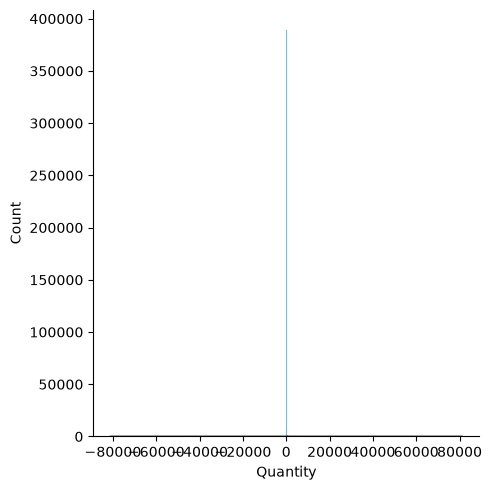

In [44]:
#visualizing the distribution
import seaborn as sns
import matplotlib.pyplot as plt
sns.displot(df_clean['Quantity'],kde=True)
plt.show()

### FILTERING THE POSITIVE QUANTITY SEPERATELY

In [45]:

df_sales=df_clean[df_clean['Quantity'] >0].copy()
df_sales["Quantity"].describe()

count    392732.000000
mean         13.153718
std         181.588420
min           1.000000
25%           2.000000
50%           6.000000
75%          12.000000
max       80995.000000
Name: Quantity, dtype: float64

In [46]:
## by this i created a separate dataframe containing only positive quantities.

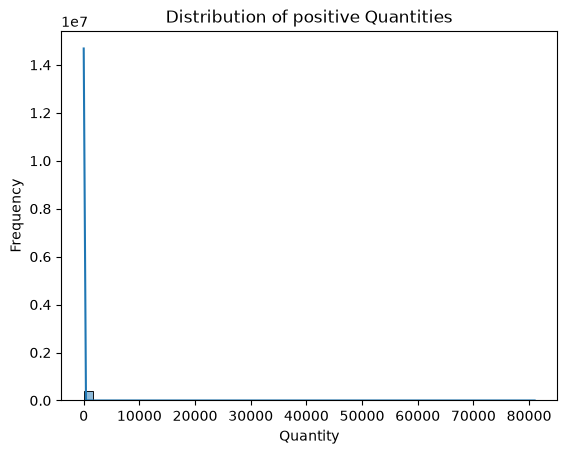

In [47]:
#visualizing the positive quantity
import seaborn as sns
import matplotlib.pyplot as plt


sns.histplot(df_sales['Quantity'],bins=50,kde=True)
plt.title("Distribution of positive Quantities")
plt.xlabel('Quantity')
plt.ylabel('Frequency')
plt.show()

#### 9,251 invoices start with C,which indicates cacellation invoices in this dataset.


In [48]:
#checking cancellation records
df_clean['Invoice']=df_clean['InvoiceNo'].astype(str)
df_cancelled=df_clean[df_clean['InvoiceNo'].str.startswith('C')].copy()
df_cancelled.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Invoice
141,C536379,D,Discount,-1,01-12-2010 9.41,27.50,14527.0,United Kingdom,C536379
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,01-12-2010 9.49,4.65,15311.0,United Kingdom,C536383
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,01-12-2010 10.24,1.65,17548.0,United Kingdom,C536391
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,01-12-2010 10.24,0.29,17548.0,United Kingdom,C536391
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,01-12-2010 10.24,0.29,17548.0,United Kingdom,C536391


### IDENTIFYING EXTREME VALUES IN QUANTITY

In [49]:
df_sales['Quantity'].quantile([0.90,0.95,0.99,0.995,1.00])

0.900       24.0
0.950       36.0
0.990      120.0
0.995      200.0
1.000    80995.0
Name: Quantity, dtype: float64

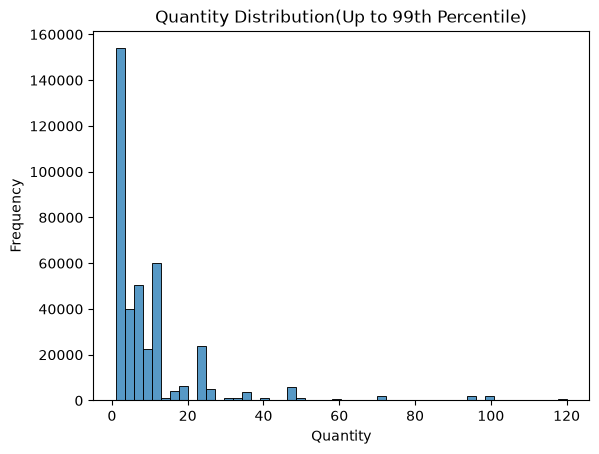

In [50]:
#visualizing the distribution
upper_limit=df_sales['Quantity'].quantile(0.99)
df_sales_visual = df_sales[df_sales['Quantity'] <= upper_limit]

sns.histplot(df_sales_visual['Quantity'],bins=50)

plt.title('Quantity Distribution(Up to 99th Percentile)')
plt.xlabel('Quantity')
plt.ylabel('Frequency')
plt.show()

###### This histogram tell that,
###### 1.High Frequency at lower quantities: most transactions have quantities between 1 and 10.
###### 2.Extreme values:Some transactions have quantities approaching 100.
###### 3.Uneven distribution: the data is not normally distributed.It is positively ( right) skewed

In [51]:
#some customers purchases small quantities of products ,while a few customers purchase products in bulk.

In [52]:
df_sales_visual['Quantity'].sort_values(ascending=False).head(15)

47847     120
340679    120
317550    120
340680    120
323065    120
261829    120
96        120
353155    120
426784    120
58116     120
220489    120
58096     120
58095     120
540065    120
284519    120
Name: Quantity, dtype: int64

### INVESTIGATING THE EXTREME VALUES

In [53]:
df_sales[df_sales['Quantity'] > 100][
    ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'UnitPrice']
].sort_values(by='Quantity', ascending=False).head(15)

,InvoiceNo,StockCode,Description,Quantity,UnitPrice
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,0.00
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21
206121,554868,22197,SMALL POPCORN HOLDER,4300,0.72
97432,544612,22053,EMPIRE DESIGN ROSETTE,3906,0.82
270885,560599,18007,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,0.06
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10
160546,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10
433788,573995,16014,SMALL CHINESE STYLE SCISSOR,3000,0.32


In [54]:
(df_sales['Quantity']>100).sum()  #records of quantity above 100.

np.int64(4663)

In [55]:
(df_sales['Quantity']>100).mean()*100 #its percentage

np.float64(1.187323671103959)

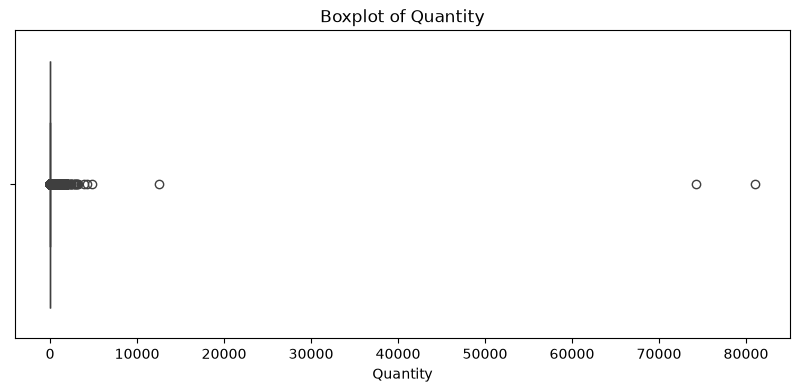

In [56]:
#checking extreme quantities with boxplot
plt.figure(figsize=(10,4))
sns.boxplot(x=df_sales['Quantity'])
plt.title("Boxplot of Quantity")
plt.xlabel('Quantity')
plt.show()

##### The box plot reveals several extreme values in the Quantity column.
##### Most observations are concentrated within smaller range,while a few unusually large extend far towards the right.
##### This indicates a highly positively skewed distribution and the presence of potential outliers.

In [57]:
#IQR
Q1 = df_sales['Quantity'].quantile(0.25)
Q3 = df_sales['Quantity'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 2.0
Q3: 12.0
IQR: 10.0
Lower Bound: -13.0
Upper Bound: 27.0


Q1 = 1: 25% of the observations have quantities up to 1.
    
 Q3 = 11: 75% of the observations have quantities up to 11.
    
IQR = 10: The middle 50% of observations are spread across a range of 10 units.
    
Upper Bound = 26: Values above 26 are classified as potential outliers using the IQR method.

In [58]:
#count potential outliers
outliers = df_sales[(df_sales['Quantity'] < lower_bound)|(df_sales['Quantity']>upper_bound)]
print("Number of potential outliers:",len(outliers))



Number of potential outliers: 25625


In [59]:
#calculating their percentage
print("Percentage of potential outliers:",(len(outliers)/len(df_sales))*100)

Percentage of potential outliers: 6.52480571993115


In [60]:
#inspect potential outliers
outliers['Quantity'].describe()


count    25625.000000
mean        99.956644
std        704.761668
min         28.000000
25%         40.000000
50%         48.000000
75%        100.000000
max      80995.000000
Name: Quantity, dtype: float64

In [61]:
outliers['Quantity'].sort_values(ascending=False).head(20)

540421    80995
61619     74215
502122    12540
421632     4800
206121     4300
97432      3906
270885     3186
160546     3114
52711      3114
433788     3000
291249     2880
4945       2880
201149     2700
80742      2592
87631      2400
421601     2400
32671      2400
91772      2400
125282     2160
437480     2100
Name: Quantity, dtype: int64

In [62]:
outliers[['InvoiceNo', 'StockCode', 'Description', 'Quantity']].sort_values(
    by='Quantity', ascending=False
).head(20)

,InvoiceNo,StockCode,Description,Quantity
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800
206121,554868,22197,SMALL POPCORN HOLDER,4300
97432,544612,22053,EMPIRE DESIGN ROSETTE,3906
270885,560599,18007,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186
160546,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114
433788,573995,16014,SMALL CHINESE STYLE SCISSOR,3000


In [63]:
df_clean = df_sales[(df_sales['Quantity'] >=lower_bound)&(df_sales['Quantity'] <= upper_bound)].copy()

In [64]:
#check the dataset
print("Original dataset:",df_sales.shape)
print("After removing outliers:",df_clean.shape)

Original dataset: (392732, 8)
After removing outliers: (367107, 8)


VISUALIZE THE CLEANED DATASET

Text(0.5, 1.0, 'Quantity Distribution After Outlier Removal')

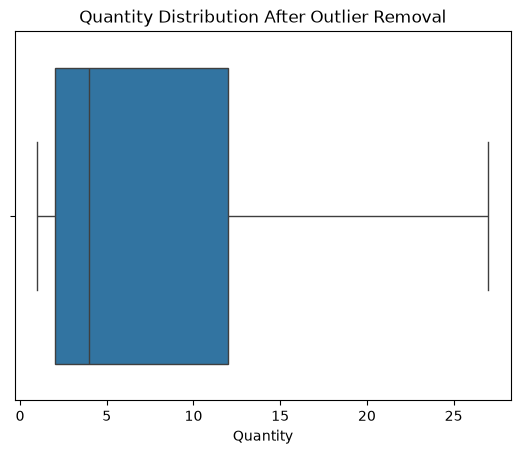

In [65]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.boxplot(x=df_clean['Quantity'])
plt.title("Quantity Distribution After Outlier Removal")

In [66]:
print("Remaining outliers:",((df_clean['Quantity']<lower_bound)|(df_clean['Quantity']>upper_bound)).sum())

Remaining outliers: 0


### FEATURE SELECTION

selecting relevant features for demand forecasting

In [67]:
df_model = df_clean[['InvoiceDate','StockCode','Quantity','UnitPrice']].copy()

In [68]:
df_model.info()

<class 'pandas.DataFrame'>
Index: 367107 entries, 0 to 541908
Data columns (total 4 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceDate  367107 non-null  str    
 1   StockCode    367107 non-null  str    
 2   Quantity     367107 non-null  int64  
 3   UnitPrice    367107 non-null  float64
dtypes: float64(1), int64(1), str(2)
memory usage: 14.0 MB


#invoicedate is currently string so i am coverting it into datetime to perform time based analysis.

#for ,
extracting month and year
identify daily and monthly sales
analyse demand trends over time
create forecasting fetures

In [69]:
df_model['InvoiceDate'] = pd.to_datetime(
    df_model['InvoiceDate'],
    format='%d-%m-%Y %H.%M'
)

In [70]:
df_model.info()

<class 'pandas.DataFrame'>
Index: 367107 entries, 0 to 541908
Data columns (total 4 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceDate  367107 non-null  datetime64[us]
 1   StockCode    367107 non-null  str           
 2   Quantity     367107 non-null  int64         
 3   UnitPrice    367107 non-null  float64       
dtypes: datetime64[us](1), float64(1), int64(1), str(1)
memory usage: 14.0 MB


In [71]:
df_model.head(15)

,InvoiceDate,StockCode,Quantity,UnitPrice
0,2010-12-01 08:26:00,85123A,6,2.55
1,2010-12-01 08:26:00,71053,6,3.39
2,2010-12-01 08:26:00,84406B,8,2.75
3,2010-12-01 08:26:00,84029G,6,3.39
4,2010-12-01 08:26:00,84029E,6,3.39
5,2010-12-01 08:26:00,22752,2,7.65
6,2010-12-01 08:26:00,21730,6,4.25
7,2010-12-01 08:28:00,22633,6,1.85
8,2010-12-01 08:28:00,22632,6,1.85
10,2010-12-01 08:34:00,22745,6,2.10


In [72]:
#extract year
df_model['Year'] = df_model['InvoiceDate'].dt.year

#dt-accesses dateime properties.

#.year - extracts the year

In [73]:
#extracting month
df_model['Month'] = df_model['InvoiceDate'].dt.month

In [74]:
#extracting day
df_model['Day'] = df_model['InvoiceDate'].dt.day

In [75]:
#extracting day of he week
df_model['Day of week'] = df_model['InvoiceDate'].dt.dayofweek

In [76]:
df_model.head(20)

,InvoiceDate,StockCode,Quantity,UnitPrice,Year,Month,Day,Day of week
0,2010-12-01 08:26:00,85123A,6,2.55,2010,12,1,2
1,2010-12-01 08:26:00,71053,6,3.39,2010,12,1,2
2,2010-12-01 08:26:00,84406B,8,2.75,2010,12,1,2
3,2010-12-01 08:26:00,84029G,6,3.39,2010,12,1,2
4,2010-12-01 08:26:00,84029E,6,3.39,2010,12,1,2
5,2010-12-01 08:26:00,22752,2,7.65,2010,12,1,2
6,2010-12-01 08:26:00,21730,6,4.25,2010,12,1,2
7,2010-12-01 08:28:00,22633,6,1.85,2010,12,1,2
8,2010-12-01 08:28:00,22632,6,1.85,2010,12,1,2
10,2010-12-01 08:34:00,22745,6,2.10,2010,12,1,2


In [77]:
df_model.info()

<class 'pandas.DataFrame'>
Index: 367107 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceDate  367107 non-null  datetime64[us]
 1   StockCode    367107 non-null  str           
 2   Quantity     367107 non-null  int64         
 3   UnitPrice    367107 non-null  float64       
 4   Year         367107 non-null  int32         
 5   Month        367107 non-null  int32         
 6   Day          367107 non-null  int32         
 7   Day of week  367107 non-null  int32         
dtypes: datetime64[us](1), float64(1), int32(4), int64(1), str(1)
memory usage: 19.6 MB


In [78]:
df_model.columns

Index(['InvoiceDate', 'StockCode', 'Quantity', 'UnitPrice', 'Year', 'Month',
       'Day', 'Day of week'],
      dtype='str')

#### AGGREGATE DAILY DEMAND

In [79]:
daily_demand = df_model.groupby(['StockCode','InvoiceDate'])['Quantity'].sum().reset_index()

In [80]:
daily_demand.head()

,StockCode,InvoiceDate,Quantity
0,10002,2010-12-01 09:45:00,12
1,10002,2010-12-03 11:19:00,1
2,10002,2010-12-05 11:02:00,1
3,10002,2010-12-06 08:42:00,24
4,10002,2010-12-08 12:24:00,12


daily demand aggregation means calculating the total quantity of a particular product
sold on a particular day.
    
The objective is to predict product demand.Therefore,we need to know the total quantity sold per product per day rather than individual transactions.

In [81]:
#checking the column names
daily_demand.columns

Index(['StockCode', 'InvoiceDate', 'Quantity'], dtype='str')

In [82]:
daily_demand['Invoicedate'] = pd.to_datetime(daily_demand['InvoiceDate'])

In [83]:
#extracting date features
daily_demand['Year'] = daily_demand['InvoiceDate'].dt.year
daily_demand['Month'] = daily_demand['InvoiceDate'].dt.month
daily_demand['Day'] = daily_demand['Invoicedate'].dt.day
daily_demand['Dayofweek']=daily_demand['InvoiceDate'].dt.dayofweek

In [84]:
daily_demand.head()

,StockCode,InvoiceDate,Quantity,Invoicedate,Year,Month,Day,Dayofweek
0,10002,2010-12-01 09:45:00,12,2010-12-01 09:45:00,2010,12,1,2
1,10002,2010-12-03 11:19:00,1,2010-12-03 11:19:00,2010,12,3,4
2,10002,2010-12-05 11:02:00,1,2010-12-05 11:02:00,2010,12,5,6
3,10002,2010-12-06 08:42:00,24,2010-12-06 08:42:00,2010,12,6,0
4,10002,2010-12-08 12:24:00,12,2010-12-08 12:24:00,2010,12,8,2


In [85]:
#checking the actual column names
daily_demand.columns.tolist()

['StockCode',
 'InvoiceDate',
 'Quantity',
 'Invoicedate',
 'Year',
 'Month',
 'Day',
 'Dayofweek']

In [86]:
#removing the duplicate invoice
daily_demand.drop(columns=['Invoicedate'],inplace=True)

In [87]:
daily_demand.columns.tolist()

['StockCode', 'InvoiceDate', 'Quantity', 'Year', 'Month', 'Day', 'Dayofweek']

## FEATURE SELECTION

In [88]:
features=['StockCode','Year','Month','Day','Dayofweek']

x = daily_demand[features]   #independent variable
y = daily_demand['Quantity']  #target variable.

In [89]:
#sorting the dataset
daily_demand = daily_demand.sort_values('InvoiceDate')

#it arranges the records in chronological order(oldest to newest).We should train on past data and test on future data

### SPLITTING THE DATASET

In [90]:
split_index = int(len(daily_demand)*0.8)  
X_train = x.iloc[:split_index]  #creating training features
X_test = x.iloc[split_index:]   #creating testing features
y_train = y.iloc[:split_index]  #creating training target
y_test = y.iloc[split_index:]   #creating testing target


In [91]:
#displaying the result
print("Training rows:",len(X_train))
print("Test rows:",len(X_test))

Training rows: 289297
Test rows: 72325


In [92]:
X_train['StockCode'].nunique() #how many unique products we have

2176

In [93]:
X_train['StockCode'].dtype

<StringDtype(storage='python', na_value=nan)>

In [94]:
X_train['StockCode'].head()

0    10002
1    10002
2    10002
3    10002
4    10002
Name: StockCode, dtype: str

In [95]:
#checking all the feature column
print(X_train.columns)

#checking the data types
print(X_train.dtypes)

#checking missing values
print(X_train.isnull().sum())

Index(['StockCode', 'Year', 'Month', 'Day', 'Dayofweek'], dtype='str')
StockCode      str
Year         int32
Month        int32
Day          int32
Dayofweek    int32
dtype: object
StockCode    0
Year         0
Month        0
Day          0
Dayofweek    0
dtype: int64


## ENCODING

encoding is a preprocessing technique used to convert categorical data into numerical representations so that machine learning algorithms can process it.
Here the,stock code column contains product identifiers stored as strings.Therefore , we need to convert them into numerical values.
 The dataset contains 2,176 unique products.One-hot encoding would create 2,176 additional columns,making the dataset larger.
    Frequency Encoding represents each product using its frequency of occurence in the training dataset.

In [96]:
# Calculate the frequency of each product
stock_frequency = X_train['StockCode'].value_counts(normalize=True) 

# Replace product codes with their frequencies
X_train['StockCode'] = X_train['StockCode'].map(stock_frequency)

# Apply the same mapping to test data
X_test['StockCode'] = X_test['StockCode'].map(stock_frequency)


- value_counts() counts how often each product appears.
- normalize=True converts counts into proportions.
- map() replaces each product code with its corresponding frequency.
- We use training frequencies for both training and testing datasets to prevent data leakage.

In [97]:
#checking encoded data
print(X_train.head())

   StockCode  Year  Month  Day  Dayofweek
0   0.000149  2010     12    1          2
1   0.000149  2010     12    3          4
2   0.000149  2010     12    5          6
3   0.000149  2010     12    6          0
4   0.000149  2010     12    8          2


In [98]:
print(X_train.dtypes)

StockCode    float64
Year           int32
Month          int32
Day            int32
Dayofweek      int32
dtype: object


In [99]:
print(X_train.isnull().sum())

StockCode    0
Year         0
Month        0
Day          0
Dayofweek    0
dtype: int64


In [100]:
X_train

,StockCode,Year,Month,Day,Dayofweek
0,0.000149,2010,12,1,2
1,0.000149,2010,12,3,4
2,0.000149,2010,12,5,6
3,0.000149,2010,12,6,0
4,0.000149,2010,12,8,2
...,...,...,...,...,...
289292,0.000069,2011,10,7,4
289293,0.000069,2011,10,9,6
289294,0.000069,2011,10,9,6
289295,0.000069,2011,10,10,0
